In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns',None)
plt.style.use('seaborn-v0_8')
sns.set_palette("Blues_d")

df = pd.read_csv("C:/Users/faizs/Downloads/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset Loaded Successfully")
print(f"Shape : {df.shape}")

Dataset Loaded Successfully
Shape : (7043, 21)


In [6]:
print("FIRST 5 ROWs")
print(df.head()) 

print("\n DATA TYPEs") 
print(df.dtypes)

print("\n Basic stats ")
print(df.describe())

FIRST 5 ROWs
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No       

In [7]:
# Fix TotalCharges — convert to numeric, spaces become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many NaN values were created
print(f"TotalCharges nulls after conversion: {df['TotalCharges'].isnull().sum()}")

# Fix SeniorCitizen — convert 0/1 to No/Yes
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# Drop the 11 rows where TotalCharges is null
df = df.dropna(subset=['TotalCharges'])

# Verify
print(f"Shape after cleaning: {df.shape}")
print(f"TotalCharges dtype: {df['TotalCharges'].dtype}")
print(f"SeniorCitizen unique values: {df['SeniorCitizen'].unique()}")

TotalCharges nulls after conversion: 11
Shape after cleaning: (7032, 21)
TotalCharges dtype: float64
SeniorCitizen unique values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [8]:
print("=== NULL VALUES ===")
print(df.isnull().sum())

print("\n=== DUPLICATE ROWS ===")
print(f"Duplicate rows: {df.duplicated().sum()}")

print("\n=== CHURN DISTRIBUTION ===")
print(df['Churn'].value_counts())
print(f"\nChurn Rate: {df['Churn'].value_counts(normalize=True)['Yes']*100:.2f}%")

=== NULL VALUES ===
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

=== DUPLICATE ROWS ===
Duplicate rows: 0

=== CHURN DISTRIBUTION ===
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn Rate: 26.58%


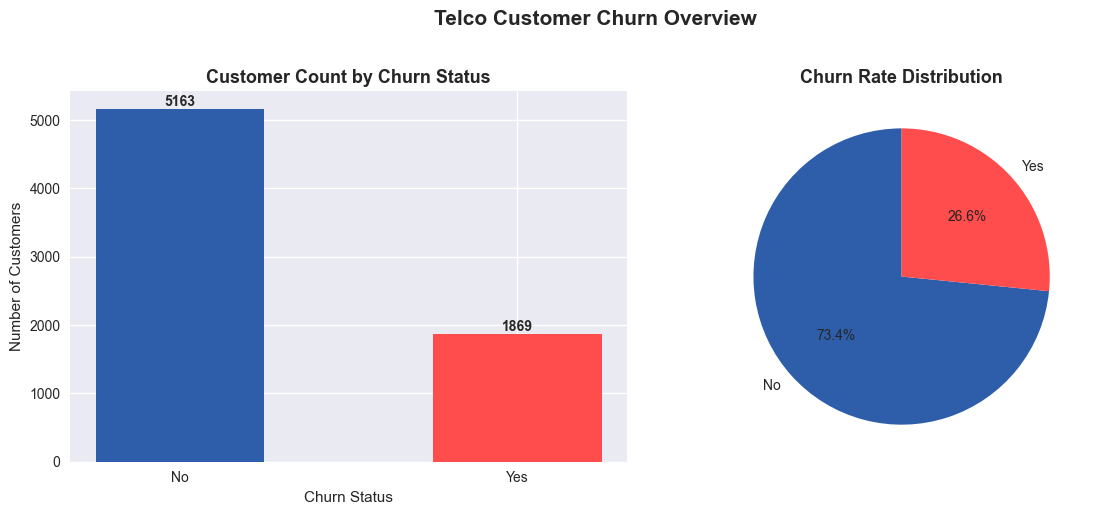

Chart saved as churn_overview.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1 — Count
churn_counts = df['Churn'].value_counts()
axes[0].bar(churn_counts.index, churn_counts.values, 
            color=['#2E5EAA', '#FF4C4C'], width=0.5)
axes[0].set_title('Customer Count by Churn Status', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Churn Status')
axes[0].set_ylabel('Number of Customers')
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

# Chart 2 — Percentage
churn_pct = df['Churn'].value_counts(normalize=True) * 100
axes[1].pie(churn_pct.values, labels=churn_pct.index, 
            autopct='%1.1f%%', colors=['#2E5EAA', '#FF4C4C'],
            startangle=90)
axes[1].set_title('Churn Rate Distribution', fontsize=13, fontweight='bold')

plt.suptitle('Telco Customer Churn Overview', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('churn_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print("Chart saved as churn_overview.png")

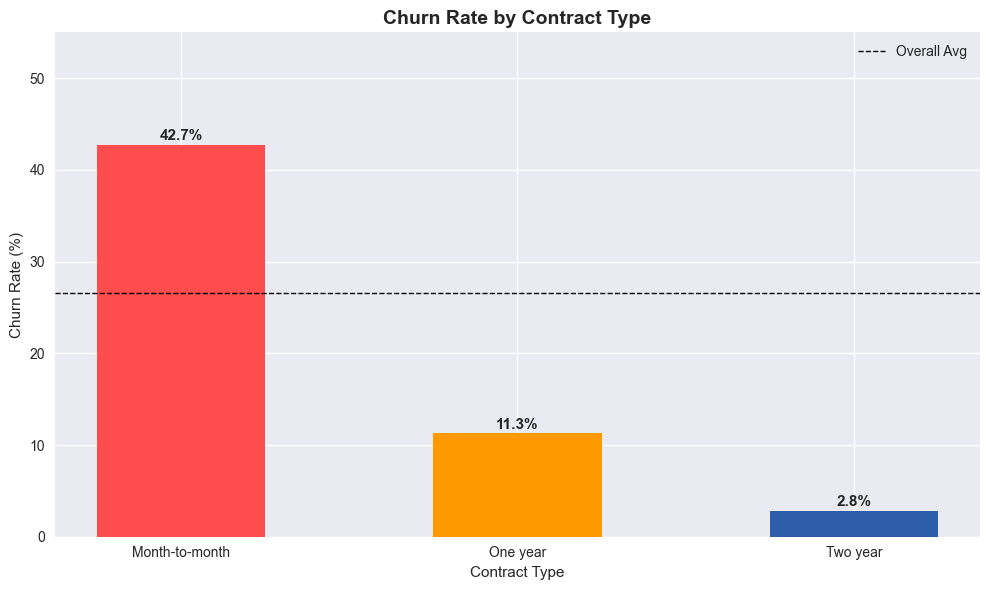

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

# Calculate churn rate by contract
contract_churn = df.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
).reset_index()
contract_churn.columns = ['Contract', 'Churn_Rate']
contract_churn = contract_churn.sort_values('Churn_Rate', ascending=False)

bars = ax.bar(contract_churn['Contract'], contract_churn['Churn_Rate'],
              color=['#FF4C4C', '#FF9900', '#2E5EAA'], width=0.5)

# Add value labels on bars
for bar, val in zip(bars, contract_churn['Churn_Rate']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', fontweight='bold', fontsize=11)

ax.set_title('Churn Rate by Contract Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Contract Type', fontsize=11)
ax.set_ylabel('Churn Rate (%)', fontsize=11)
ax.set_ylim(0, 55)
ax.axhline(y=df['Churn'].value_counts(normalize=True)['Yes']*100, 
           color='black', linestyle='--', linewidth=1, label='Overall Avg')
ax.legend()

plt.tight_layout()
plt.savefig('churn_by_contract.png', dpi=150, bbox_inches='tight')
plt.show()

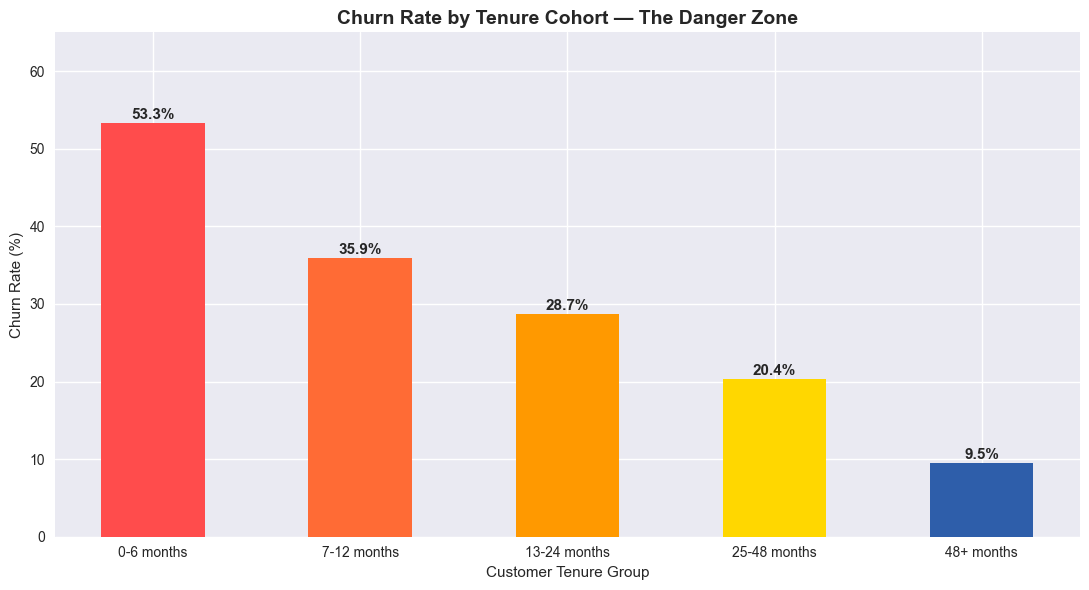

In [11]:
# Create tenure cohort column
def tenure_cohort(tenure):
    if tenure <= 6:
        return '0-6 months'
    elif tenure <= 12:
        return '7-12 months'
    elif tenure <= 24:
        return '13-24 months'
    elif tenure <= 48:
        return '25-48 months'
    else:
        return '48+ months'

df['tenure_cohort'] = df['tenure'].apply(tenure_cohort)

# Define order
cohort_order = ['0-6 months', '7-12 months', '13-24 months', '25-48 months', '48+ months']

# Calculate churn rate per cohort
cohort_churn = df.groupby('tenure_cohort')['Churn'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
).reindex(cohort_order).reset_index()
cohort_churn.columns = ['Tenure_Cohort', 'Churn_Rate']

# Plot
fig, ax = plt.subplots(figsize=(11, 6))

colors = ['#FF4C4C', '#FF6B35', '#FF9900', '#FFD700', '#2E5EAA']
bars = ax.bar(cohort_churn['Tenure_Cohort'], cohort_churn['Churn_Rate'],
              color=colors, width=0.5)

for bar, val in zip(bars, cohort_churn['Churn_Rate']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', fontweight='bold', fontsize=11)

ax.set_title('Churn Rate by Tenure Cohort — The Danger Zone', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Customer Tenure Group', fontsize=11)
ax.set_ylabel('Churn Rate (%)', fontsize=11)
ax.set_ylim(0, 65)

plt.tight_layout()
plt.savefig('churn_by_tenure.png', dpi=150, bbox_inches='tight')
plt.show()

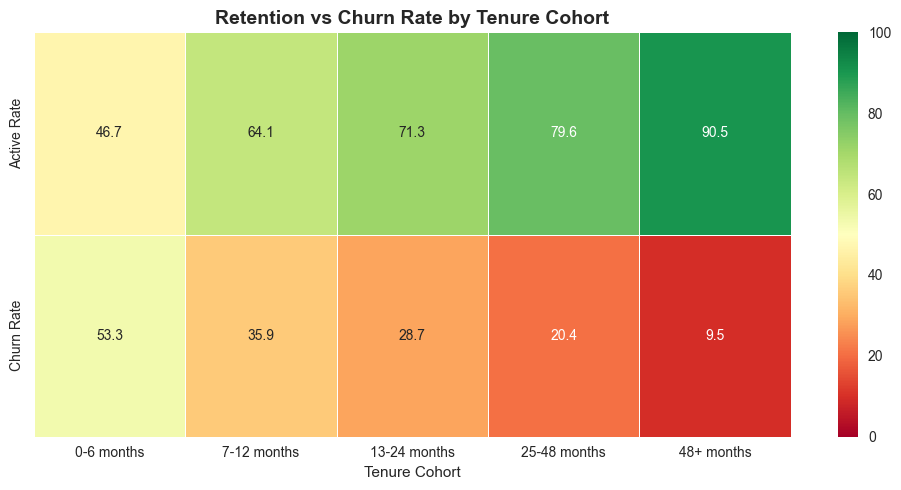

In [12]:
# Create cohort based on tenure groups
# We simulate cohort retention using tenure + churn data

cohort_retention = df.groupby('tenure_cohort').apply(
    lambda x: (x['Churn'] == 'No').sum() / len(x) * 100
).reindex(cohort_order)

# Build retention matrix across cohorts
retention_matrix = pd.DataFrame({
    'Active Rate': cohort_retention,
    'Churn Rate': 100 - cohort_retention
}, index=cohort_order)

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(retention_matrix.T, 
            annot=True, 
            fmt='.1f',
            cmap='RdYlGn',
            linewidths=0.5,
            ax=ax,
            vmin=0, 
            vmax=100)

ax.set_title('Retention vs Churn Rate by Tenure Cohort', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Tenure Cohort', fontsize=11)
ax.set_ylabel('')

plt.tight_layout()
plt.savefig('retention_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# Current state
total_customers = len(df)
critical_customers = len(df[
    (df['Contract'] == 'Month-to-month') & 
    (df['tenure'] <= 12) & 
    (df['Churn'] == 'No')
])
critical_revenue = df[
    (df['Contract'] == 'Month-to-month') & 
    (df['tenure'] <= 12) & 
    (df['Churn'] == 'No')
]['MonthlyCharges'].sum()

current_churn_rate = (df['Churn'] == 'Yes').sum() / len(df)
avg_monthly_charges = df['MonthlyCharges'].mean()

# Scenario — if we reduce early churn by 10%
improved_churn_rate = current_churn_rate * 0.90
customers_saved = total_customers * (current_churn_rate - improved_churn_rate)
revenue_saved_monthly = customers_saved * avg_monthly_charges
revenue_saved_annually = revenue_saved_monthly * 12

print("=== SCENARIO ANALYSIS ===")
print(f"Current churn rate: {current_churn_rate*100:.2f}%")
print(f"Improved churn rate (10% reduction): {improved_churn_rate*100:.2f}%")
print(f"Customers saved per month: {customers_saved:.0f}")
print(f"Monthly revenue recovered: ₹{revenue_saved_monthly:,.0f}")
print(f"Annual revenue recovered: ₹{revenue_saved_annually:,.0f}")
print(f"\nCritical segment customers: {critical_customers}")
print(f"Critical segment monthly revenue at risk: ₹{critical_revenue:,.0f}")

=== SCENARIO ANALYSIS ===
Current churn rate: 26.58%
Improved churn rate (10% reduction): 23.92%
Customers saved per month: 187
Monthly revenue recovered: ₹12,111
Annual revenue recovered: ₹145,329

Critical segment customers: 970
Critical segment monthly revenue at risk: ₹47,785


In [14]:
# Add all engineered columns to export
df['service_adoption'] = np.where(
    (df['OnlineSecurity'] == 'Yes') & (df['TechSupport'] == 'Yes'), 'Both Services',
    np.where(
        (df['OnlineSecurity'] == 'Yes') | (df['TechSupport'] == 'Yes'), 'One Service',
        'No Services'
    )
)

df['payment_type'] = np.where(
    df['PaymentMethod'].isin(['Bank transfer (automatic)', 'Credit card (automatic)']),
    'Automatic', 'Manual'
)

contract_avg = df.groupby('Contract')['MonthlyCharges'].transform('mean')
df['price_position'] = np.where(
    df['MonthlyCharges'] > contract_avg, 'Above Average',
    np.where(df['MonthlyCharges'] < contract_avg, 'Below Average', 'Average')
)

# Export
df.to_csv('telco_churn_clean.csv', index=False)
print(f"Exported {len(df)} rows with {len(df.columns)} columns")
print(f"Columns: {list(df.columns)}")

Exported 7032 rows with 25 columns
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'tenure_cohort', 'service_adoption', 'payment_type', 'price_position']
